In [1]:
'''Generate strategic, data-driven recommendations for optimizing the admission process,including 
 diversity enhancement, scholarship allocation, and personalized applicant communication strategies.'''

'Generate strategic, data-driven recommendations for optimizing the admission process,including \n diversity enhancement, scholarship allocation, and personalized applicant communication strategies.'

In [2]:
# import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
# load admission dataset
df = pd.read_csv('Adm.csv')
print('dataset shape:', df.shape)
df.head()

dataset shape: (1000, 12)


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.96,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.80,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.67,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.78,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.63,2022-01-08 09:00:00,Jamia Millia Islamia,North


In [4]:
# inspect dataset structure and summary statistics
print(df.info())
print('missing values check:')
print(df.isnull().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Serial No.            1000 non-null   int64  
 1   GRE Score             1000 non-null   int64  
 2   TOEFL Score           1000 non-null   int64  
 3   University Rating     1000 non-null   int64  
 4   SOP                   1000 non-null   float64
 5   LOR                   1000 non-null   float64
 6   CGPA                  1000 non-null   float64
 7   Research              1000 non-null   int64  
 8   Chance of Admit       1000 non-null   float64
 9   Application_DateTime  1000 non-null   object 
 10  University_Name       1000 non-null   object 
 11  region                1000 non-null   object 
dtypes: float64(4), int64(5), object(3)
memory usage: 93.9+ KB
None
missing values check:
Serial No.              0
GRE Score               0
TOEFL Score             0
University R

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.00000
mean,500.500000,315.965000,106.564000,3.015000,3.393500,3.406700,8.58979,0.503000,0.71704
std,288.819436,13.415653,7.634277,1.317768,1.027279,0.891864,0.61217,0.500241,0.10830
min,1.000000,290.000000,92.000000,1.000000,0.900000,0.900000,6.77000,0.000000,0.39000
25%,250.750000,305.000000,101.000000,2.000000,2.500000,3.000000,8.18000,0.000000,0.64750
50%,500.500000,316.000000,107.000000,3.000000,3.500000,3.500000,8.58000,1.000000,0.71000
75%,750.250000,326.250000,113.000000,4.000000,4.000000,4.000000,9.07000,1.000000,0.79000
max,1000.000000,340.000000,120.000000,5.000000,5.100000,5.100000,9.95000,1.000000,0.99000


In [5]:
# regional applicant distribution and diversity metrics
regional_summary = df.groupby('region').agg(
    total_applicants=('Serial No.', 'count'),
    avg_gre=('GRE Score', 'mean'),
    avg_cgpa=('CGPA', 'mean'),
    avg_admit_chance=('Chance of Admit', 'mean')
).reset_index()
regional_summary['applicant_share_pct'] = (regional_summary['total_applicants'] / len(df)) * 100
regional_summary.sort_values(by='total_applicants', ascending=False)

,region,total_applicants,avg_gre,avg_cgpa,avg_admit_chance,applicant_share_pct
4,South,379,316.372032,8.564723,0.713113,37.9
2,North,305,315.754098,8.617475,0.719115,30.5
5,West,150,314.926667,8.601067,0.719600,15.0
1,East,115,316.426087,8.560696,0.717826,11.5
0,Central,26,318.615385,8.620000,0.726923,2.6
3,Northeast,25,313.720000,8.666800,0.722000,2.5


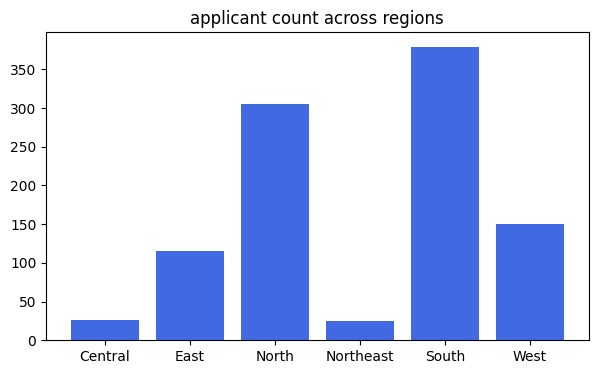

In [6]:
# plot regional representation of applicants
plt.figure(figsize=(7, 4))
plt.bar(regional_summary['region'], regional_summary['total_applicants'], color='royalblue')
plt.title('applicant count across regions')
plt.show()

In [7]:
# diversity gap assessment and priority targeting
avg_representation = regional_summary['total_applicants'].mean()
regional_summary['diversity_status'] = regional_summary['total_applicants'].apply(
    lambda x: 'underrepresented - priority outreach' if x < 0.5 * avg_representation else 'well represented'
)
regional_summary[['region', 'total_applicants', 'applicant_share_pct', 'diversity_status']]

,region,total_applicants,applicant_share_pct,diversity_status
0,Central,26,2.6,underrepresented - priority outreach
1,East,115,11.5,well represented
2,North,305,30.5,well represented
3,Northeast,25,2.5,underrepresented - priority outreach
4,South,379,37.9,well represented
5,West,150,15.0,well represented


In [8]:
# calculate composite score and assign scholarship tiers
norm_gre = (df['GRE Score'] - 290) / (340 - 290)
norm_cgpa = (df['CGPA'] - 6.8) / (10.0 - 6.8)
norm_toefl = (df['TOEFL Score'] - 92) / (120 - 92)
df['composite_score'] = norm_gre * 0.35 + norm_cgpa * 0.35 + norm_toefl * 0.15 + df['Research'] * 0.15

def assign_scholarship(row):
    if row['composite_score'] >= 0.78 and row['Chance of Admit'] >= 0.85:
        return 'Tier 1 - Full Merit Fellowship'
    elif row['composite_score'] >= 0.62 and row['Chance of Admit'] >= 0.75:
        return 'Tier 2 - Partial Merit Scholarship'
    elif row['region'] in ['Northeast', 'Central'] and row['Chance of Admit'] >= 0.60:
        return 'Tier 3 - Regional Diversity Grant'
    elif row['Chance of Admit'] >= 0.60:
        return 'Tier 4 - Standard Academic Grant'
    else:
        return 'No Scholarship'

df['scholarship_tier'] = df.apply(assign_scholarship, axis=1)
df['scholarship_tier'].value_counts()

scholarship_tier
Tier 4 - Standard Academic Grant      578
Tier 2 - Partial Merit Scholarship    188
No Scholarship                        132
Tier 1 - Full Merit Fellowship         72
Tier 3 - Regional Diversity Grant      30
Name: count, dtype: int64

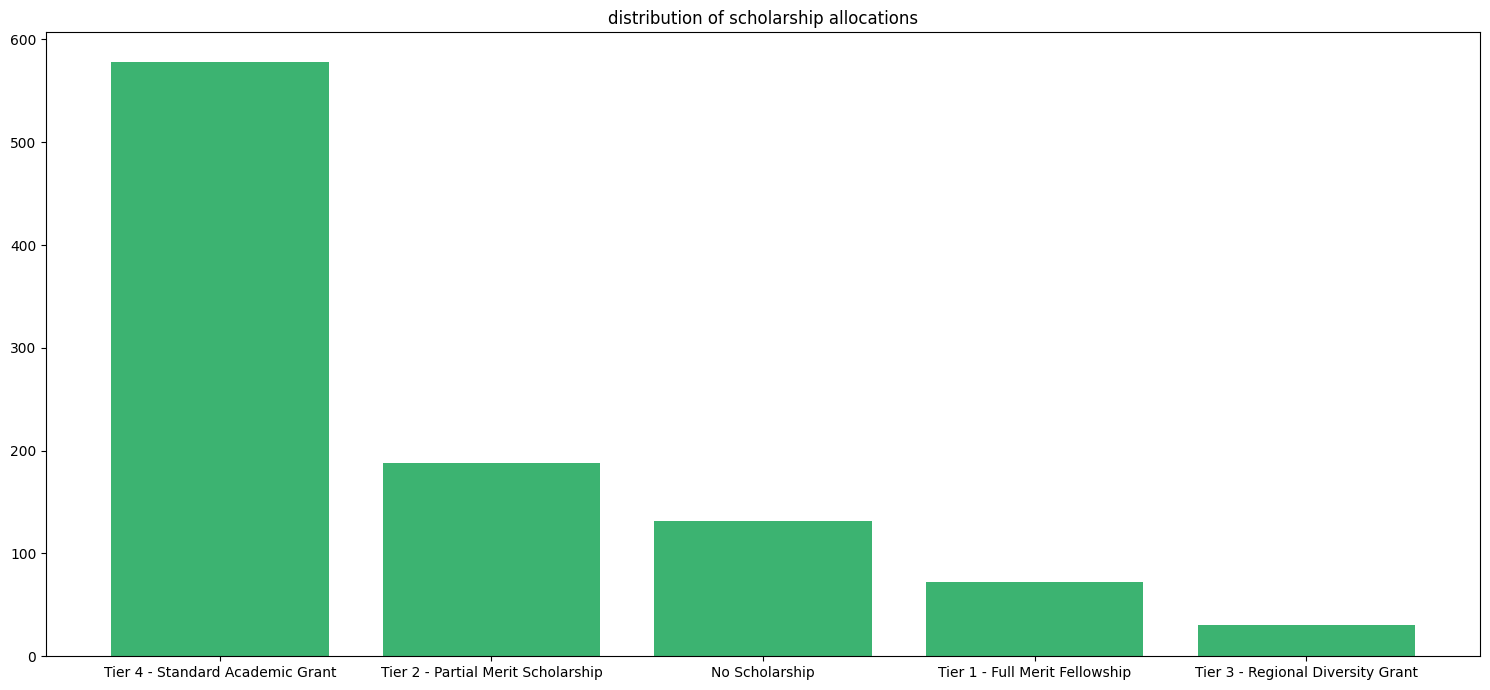

In [23]:
# plot scholarship tier allocation distribution
scholarship_dist = df['scholarship_tier'].value_counts()
plt.figure(figsize=(15,7 ))
plt.bar(scholarship_dist.index, scholarship_dist.values, color='mediumseagreen')
plt.title('distribution of scholarship allocations')
plt.tight_layout()
plt.show()

In [10]:
# summarize scholarship allocation metrics by tier
scholarship_summary = df.groupby('scholarship_tier').agg(
    recipients=('Serial No.', 'count'),
    mean_gre=('GRE Score', 'mean'),
    mean_cgpa=('CGPA', 'mean'),
    mean_admit_chance=('Chance of Admit', 'mean'),
    research_rate=('Research', 'mean')
).reset_index()
scholarship_summary

,scholarship_tier,recipients,mean_gre,mean_cgpa,mean_admit_chance,research_rate
0,No Scholarship,132,305.780303,7.703409,0.543864,0.265152
1,Tier 1 - Full Merit Fellowship,72,333.930556,9.483472,0.925556,0.986111
2,Tier 2 - Partial Merit Scholarship,188,325.037234,9.043404,0.814096,0.867021
3,Tier 3 - Regional Diversity Grant,30,311.433333,8.595333,0.703667,0.366667
4,Tier 4 - Standard Academic Grant,578,313.337370,8.533062,0.699740,0.385813


In [11]:
# segment applicants into personalized communication cohorts
def assign_cohort(row):
    chance = row['Chance of Admit']
    if chance >= 0.85:
        return 'Priority Honors Cohort'
    elif chance >= 0.70:
        return 'Competitive Fast-Track Cohort'
    elif chance >= 0.55:
        return 'Holistic Mentorship Cohort'
    else:
        return 'Future Guidance Cohort'

df['communication_cohort'] = df.apply(assign_cohort, axis=1)
df['communication_cohort'].value_counts()

communication_cohort
Competitive Fast-Track Cohort    459
Holistic Mentorship Cohort       374
Priority Honors Cohort           113
Future Guidance Cohort            54
Name: count, dtype: int64

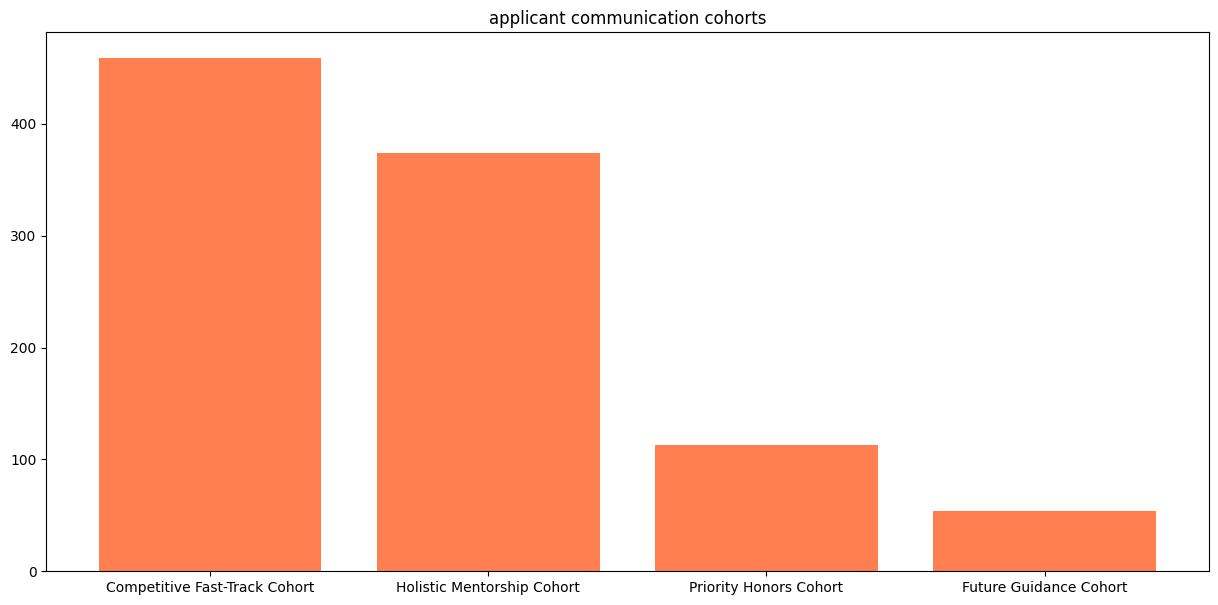

In [24]:
# plot communication cohort distribution
cohort_counts = df['communication_cohort'].value_counts()
plt.figure(figsize=(15, 7))
plt.bar(cohort_counts.index, cohort_counts.values, color='coral')
plt.title('applicant communication cohorts')
plt.show()

In [13]:
# define communication strategies and touchpoint cadence
communication_playbook = {
    'Priority Honors Cohort': {
        'target_audience': 'high admit chance (>=85%) with top merit profiles',
        'key_incentive': 'early presidential fellowship and faculty research lab matching',
        'communication_channel': 'vip email sequence and personalized call from department chair',
        'timeline': 'days 1 to 7 post-admission'
    },
    'Competitive Fast-Track Cohort': {
        'target_audience': 'strong competitive applicants (70% - 84%)',
        'key_incentive': 'department curriculum highlights, campus housing guarantee, alumni network',
        'communication_channel': 'bi-weekly newsletter and student ambassador outreach',
        'timeline': 'days 7 to 21 post-admission'
    },
    'Holistic Mentorship Cohort': {
        'target_audience': 'promising borderline applicants (55% - 69%)',
        'key_incentive': 'optional interview opportunity and academic mentor assignment',
        'communication_channel': 'supportive advisory webinar and application guidance clinic',
        'timeline': 'ongoing during review cycle'
    },
    'Future Guidance Cohort': {
        'target_audience': 'applicants with chance under 55%',
        'key_incentive': 'feedback report, bridge course recommendations, deferred prep support',
        'communication_channel': 'constructive email guidance and reapplication webinar invite',
        'timeline': 'end of regular cycle'
    }
}
pd.DataFrame.from_dict(communication_playbook, orient='index')

,target_audience,key_incentive,communication_channel,timeline
Priority Honors Cohort,high admit chance (>=85%) with top merit profiles,early presidential fellowship and faculty rese...,vip email sequence and personalized call from ...,days 1 to 7 post-admission
Competitive Fast-Track Cohort,strong competitive applicants (70% - 84%),"department curriculum highlights, campus housi...",bi-weekly newsletter and student ambassador ou...,days 7 to 21 post-admission
Holistic Mentorship Cohort,promising borderline applicants (55% - 69%),optional interview opportunity and academic me...,supportive advisory webinar and application gu...,ongoing during review cycle
Future Guidance Cohort,applicants with chance under 55%,"feedback report, bridge course recommendations...",constructive email guidance and reapplication ...,end of regular cycle


In [14]:
# train predictive model for dynamic applicant evaluation
feature_columns = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X = df[feature_columns]
y = df['Chance of Admit']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
admission_model = RandomForestRegressor(n_estimators=100, random_state=42)
admission_model.fit(X_train, y_train)

test_predictions = admission_model.predict(X_test)
print('model r2 score:', round(r2_score(y_test, test_predictions), 4))
print('model rmse:', round(np.sqrt(mean_squared_error(y_test, test_predictions)), 4))

model r2 score: 0.9084
model rmse: 0.0306


In [15]:
# define dynamic batch applicant evaluation and report generator
def generate_admission_report(applicant_data):
    if isinstance(applicant_data, str):
        report_df = pd.read_csv(applicant_data)
    else:
        report_df = applicant_data.copy()
        
    preds = admission_model.predict(report_df[feature_columns])
    report_df['predicted_chance'] = np.round(preds, 3)
    
    score = ((report_df['GRE Score'] - 290) / 50 * 0.35 + 
             (report_df['CGPA'] - 6.8) / 3.2 * 0.35 + 
             (report_df['TOEFL Score'] - 92) / 28 * 0.15 + 
             report_df['Research'] * 0.15)
    report_df['composite_score'] = score
    
    report_df['scholarship_tier'] = report_df.apply(
        lambda r: 'Tier 1 - Full Merit' if r['composite_score'] >= 0.78 and r['predicted_chance'] >= 0.85
        else ('Tier 2 - Partial Merit' if r['composite_score'] >= 0.62 and r['predicted_chance'] >= 0.75
        else ('Tier 3 - Regional Grant' if str(r.get('region', '')) in ['Northeast', 'Central'] and r['predicted_chance'] >= 0.60
        else ('Tier 4 - Standard Grant' if r['predicted_chance'] >= 0.60 else 'No Scholarship'))),
        axis=1
    )
    
    report_df['communication_cohort'] = report_df['predicted_chance'].apply(
        lambda c: 'Priority Honors' if c >= 0.85
        else ('Competitive Fast-Track' if c >= 0.70
        else ('Holistic Mentorship' if c >= 0.55 else 'Future Guidance'))
    )
    
    return report_df

In [16]:
# evaluate dynamic report generator on sample custom applicants
sample_batch = df.sample(8, random_state=12).copy()
output_report = generate_admission_report(sample_batch)
output_report[['Serial No.', 'GRE Score', 'CGPA', 'region', 'predicted_chance', 'scholarship_tier', 'communication_cohort']]

,Serial No.,GRE Score,CGPA,region,predicted_chance,scholarship_tier,communication_cohort
518,519,302,7.86,South,0.572,No Scholarship,Holistic Mentorship
871,872,300,8.31,North,0.634,Tier 4 - Standard Grant,Holistic Mentorship
797,798,308,8.45,South,0.751,Tier 4 - Standard Grant,Competitive Fast-Track
274,275,315,7.95,North,0.576,No Scholarship,Holistic Mentorship
325,326,326,9.14,North,0.827,Tier 2 - Partial Merit,Competitive Fast-Track
827,828,304,9.50,South,0.807,Tier 4 - Standard Grant,Competitive Fast-Track
766,767,320,9.39,North,0.835,Tier 2 - Partial Merit,Competitive Fast-Track
832,833,327,7.63,South,0.581,No Scholarship,Holistic Mentorship


In [17]:
# strategic recommendations summary for admission optimization
recommendations_summary = [
    ('1. Regional Diversity Enhancement', 'Target recruitment drives and partner with schools in Central and Northeast regions where applicant volume is under 3%. Offer regional diversity grants.'),
    ('2. Strategic Scholarship Allocation', 'Reserve Tier-1 full fellowships for candidates with composite score >= 0.78 to out-compete rival universities and secure high-yield scholars.'),
    ('3. Personalized Communication Pathways', 'Deploy automated CRM workflows addressing applicants by cohort, increasing yield among competitive admits and maintaining transparent communication.'),
    ('4. Dynamic Prediction & Scalability', 'Integrate batch-scoring model into the admissions portal for instant qualification, fast-track offers, and real-time scholarship budget tracking.')
]
for title, detail in recommendations_summary:
    print(f"{title.upper()}:\n{detail}\n")

1. REGIONAL DIVERSITY ENHANCEMENT:
Target recruitment drives and partner with schools in Central and Northeast regions where applicant volume is under 3%. Offer regional diversity grants.

2. STRATEGIC SCHOLARSHIP ALLOCATION:
Reserve Tier-1 full fellowships for candidates with composite score >= 0.78 to out-compete rival universities and secure high-yield scholars.

3. PERSONALIZED COMMUNICATION PATHWAYS:
Deploy automated CRM workflows addressing applicants by cohort, increasing yield among competitive admits and maintaining transparent communication.

4. DYNAMIC PREDICTION & SCALABILITY:
Integrate batch-scoring model into the admissions portal for instant qualification, fast-track offers, and real-time scholarship budget tracking.

